#Lab 6 Machine LEARNING
#####Name: Kamal Man
######Section: A
######Batch: A1
######Roll No: 11

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("seeds_new.csv")
df.columns = list(df.columns[:-1]) + ["Class"]

print("Shape:", df.shape)
print(df.head())
print("\nClass distribution:\n", df["Class"].value_counts().sort_index())
print("\nMissing values:", df.isna().sum().sum())
print(df.describe().round(3))

Shape: (210, 8)
    Area  Perimeter  Compactness  Length of kernel  Width of kernel  \
0  15.26      14.84       0.8710             5.763            3.312   
1  14.88      14.57       0.8811             5.554            3.333   
2  14.29      14.09       0.9050             5.291            3.337   
3  13.84      13.94       0.8955             5.324            3.379   
4  16.14      14.99       0.9034             5.658            3.562   

   Asymmetry coefficient  Length of kernel groove  Class  
0                  2.221                    5.220      1  
1                  1.018                    4.956      1  
2                  2.699                    4.825      1  
3                  2.259                    4.805      1  
4                  1.355                    5.175      1  

Class distribution:
 Class
1    70
2    70
3    70
Name: count, dtype: int64

Missing values: 0
          Area  Perimeter  Compactness  Length of kernel  Width of kernel  \
count  210.000    210.000    

In [ ]:
sub = df[df["Class"].isin([1, 2])]

X = sub.drop(columns="Class").values
y = np.where(sub["Class"].values == 1, 1, 0)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (112, 7) Test: (28, 7)


In [ ]:
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score

model = Perceptron(eta0=0.1, max_iter=100, tol=None, random_state=42)
model.fit(X_train, y_train)

print("Weights:", np.round(model.coef_[0], 4))
print("Bias   :", np.round(model.intercept_[0], 4))
print("Epochs run:", model.n_iter_)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

print("\nTraining accuracy: {:.2f}%".format(accuracy_score(y_train, y_pred_train) * 100))
print("Testing accuracy : {:.2f}%".format(accuracy_score(y_test, y_pred_test) * 100))

Weights: [-0.247  -0.2463  0.0779  0.7545 -0.1371 -0.146  -0.6226]
Bias   : 0.0
Epochs run: 100

Training accuracy: 100.00%
Testing accuracy : 100.00%


In [ ]:
print("eta0   | max_iter | test accuracy")
for eta in [0.001, 0.01, 0.1, 1.0]:
    for it in [5, 20, 100]:
        m = Perceptron(eta0=eta, max_iter=it, tol=None, random_state=42).fit(X_train, y_train)
        acc = accuracy_score(y_test, m.predict(X_test))
        print(f"{eta:<6} | {it:<8} | {acc*100:.2f}%")


eta0   | max_iter | test accuracy
0.001  | 5        | 100.00%
0.001  | 20       | 100.00%
0.001  | 100      | 100.00%
0.01   | 5        | 100.00%
0.01   | 20       | 100.00%
0.01   | 100      | 100.00%
0.1    | 5        | 100.00%
0.1    | 20       | 100.00%
0.1    | 100      | 100.00%
1.0    | 5        | 100.00%
1.0    | 20       | 100.00%
1.0    | 100      | 100.00%


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_test)
print("Confusion Matrix:\n", cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_test,
                            target_names=["Class 2 (0)", "Class 1 (1)"]))

Confusion Matrix:
 [[14  0]
 [ 0 14]]

Classification Report:
              precision    recall  f1-score   support

 Class 2 (0)       1.00      1.00      1.00        14
 Class 1 (1)       1.00      1.00      1.00        14

    accuracy                           1.00        28
   macro avg       1.00      1.00      1.00        28
weighted avg       1.00      1.00      1.00        28



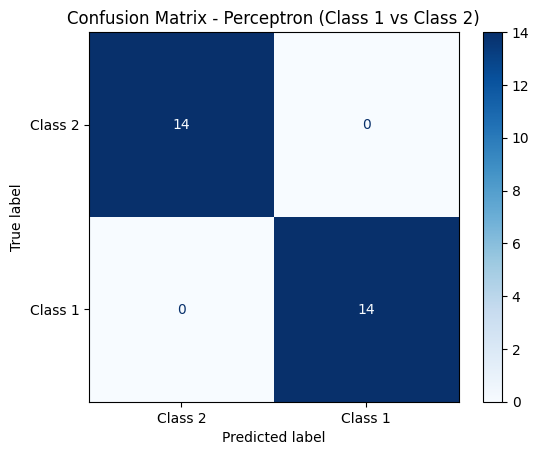

In [ ]:
plt.style.use("default")
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["Class 2", "Class 1"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Perceptron (Class 1 vs Class 2)")
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import accuracy_score, confusion_matrix

tf.random.set_seed(42)

model_tf = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(1, activation="sigmoid")
])

model_tf.compile(optimizer=keras.optimizers.SGD(learning_rate=0.1),
                 loss="binary_crossentropy",
                 metrics=["accuracy"])

model_tf.summary()

history = model_tf.fit(X_train, y_train,
                       epochs=100, batch_size=16,
                       validation_split=0.2, verbose=0)

loss, acc = model_tf.evaluate(X_test, y_test, verbose=0)
print(f"\nTest loss: {loss:.4f} | Test accuracy: {acc*100:.2f}%")

y_pred_tf = (model_tf.predict(X_test, verbose=0) > 0.5).astype(int).ravel()
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_tf))


w, b = model_tf.layers[0].get_weights()
print("Weights:", np.round(w.ravel(), 4))
print("Bias   :", np.round(b, 4))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8 (32.00 B)

 Trainable params: 8 (32.00 B)

 Non-trainable params: 0 (0.00 B)


Test loss: 0.0933 | Test accuracy: 96.43%
Confusion Matrix:
 [[13  1]
 [ 0 14]]
Weights: [-1.493  -0.9722 -0.1822 -0.3068 -1.0772 -1.2464 -1.5706]
Bias   : [0.1687]


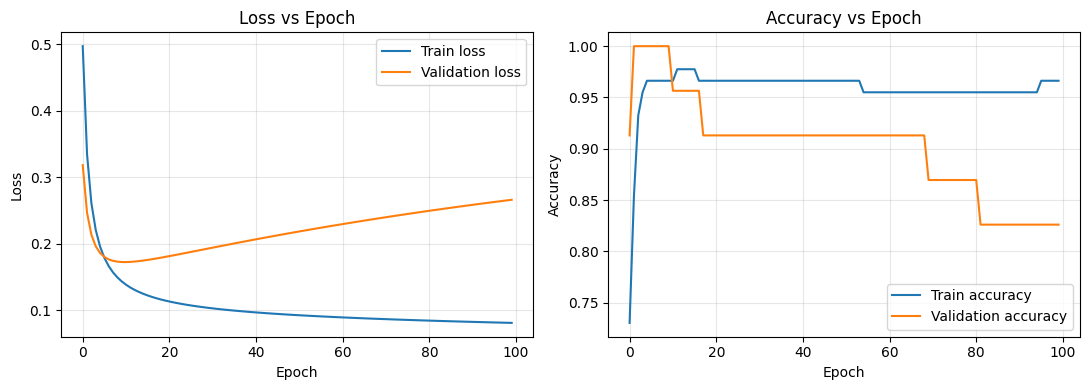

In [ ]:
plt.style.use("default")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(history.history["loss"], label="Train loss")
ax[0].plot(history.history["val_loss"], label="Validation loss")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss")
ax[0].set_title("Loss vs Epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(history.history["accuracy"], label="Train accuracy")
ax[1].plot(history.history["val_accuracy"], label="Validation accuracy")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy")
ax[1].set_title("Accuracy vs Epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

2-feature accuracy: 88.57%


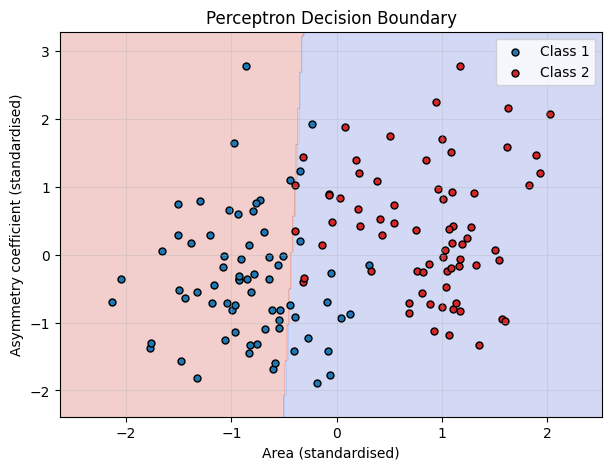

In [ ]:
from sklearn.linear_model import Perceptron
from sklearn.preprocessing import StandardScaler

sub2 = df[df["Class"].isin([1, 2])]
X2 = sub2[["Area", "Asymmetry coefficient"]].values
y2 = np.where(sub2["Class"].values == 1, 1, 0)

sc2 = StandardScaler()
X2s = sc2.fit_transform(X2)

p2 = Perceptron(eta0=0.1, max_iter=100, tol=None, random_state=42).fit(X2s, y2)
print("2-feature accuracy: {:.2f}%".format(p2.score(X2s, y2) * 100))

xx, yy = np.meshgrid(np.linspace(X2s[:, 0].min() - 0.5, X2s[:, 0].max() + 0.5, 300),
                     np.linspace(X2s[:, 1].min() - 0.5, X2s[:, 1].max() + 0.5, 300))
zz = p2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
plt.scatter(X2s[y2 == 1, 0], X2s[y2 == 1, 1], c="tab:blue", edgecolor="k", s=25, label="Class 1")
plt.scatter(X2s[y2 == 0, 0], X2s[y2 == 0, 1], c="tab:red", edgecolor="k", s=25, label="Class 2")
plt.xlabel("Area (standardised)")
plt.ylabel("Asymmetry coefficient (standardised)")
plt.title("Perceptron Decision Boundary")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [ ]:
# ---------- PART 6: All 3 classes (One-vs-Rest) ----------
# sklearn's Perceptron automatically trains one perceptron per class
from sklearn.metrics import classification_report

Xa = df.drop(columns="Class").values
ya = df["Class"].values

Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.2,
                                              random_state=42, stratify=ya)
sca = StandardScaler()
Xa_tr = sca.fit_transform(Xa_tr)
Xa_te = sca.transform(Xa_te)

multi = Perceptron(eta0=0.1, max_iter=100, tol=None, random_state=42).fit(Xa_tr, ya_tr)
pred_m = multi.predict(Xa_te)

print("3-class test accuracy: {:.2f}%".format(accuracy_score(ya_te, pred_m) * 100))
print("Confusion Matrix:\n", confusion_matrix(ya_te, pred_m))
print(classification_report(ya_te, pred_m))

3-class test accuracy: 95.24%
Confusion Matrix:
 [[12  0  2]
 [ 0 14  0]
 [ 0  0 14]]
              precision    recall  f1-score   support

           1       1.00      0.86      0.92        14
           2       1.00      1.00      1.00        14
           3       0.88      1.00      0.93        14

    accuracy                           0.95        42
   macro avg       0.96      0.95      0.95        42
weighted avg       0.96      0.95      0.95        42



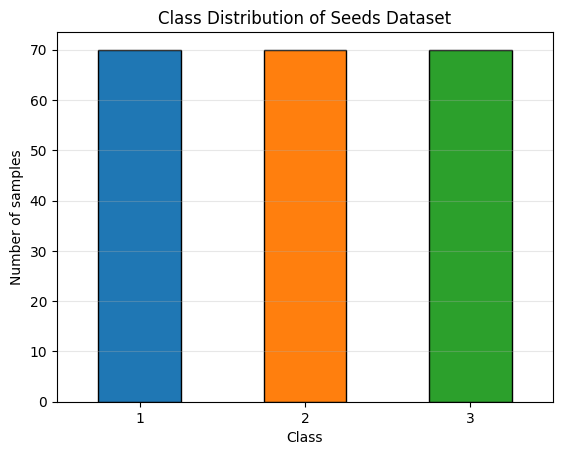

In [ ]:
plt.style.use("default")
df["Class"].value_counts().sort_index().plot(kind="bar", color=["tab:blue", "tab:orange", "tab:green"], edgecolor="k")
plt.xlabel("Class"); plt.ylabel("Number of samples")
plt.title("Class Distribution of Seeds Dataset")
plt.xticks(rotation=0); plt.grid(axis="y", alpha=0.3)
plt.show()

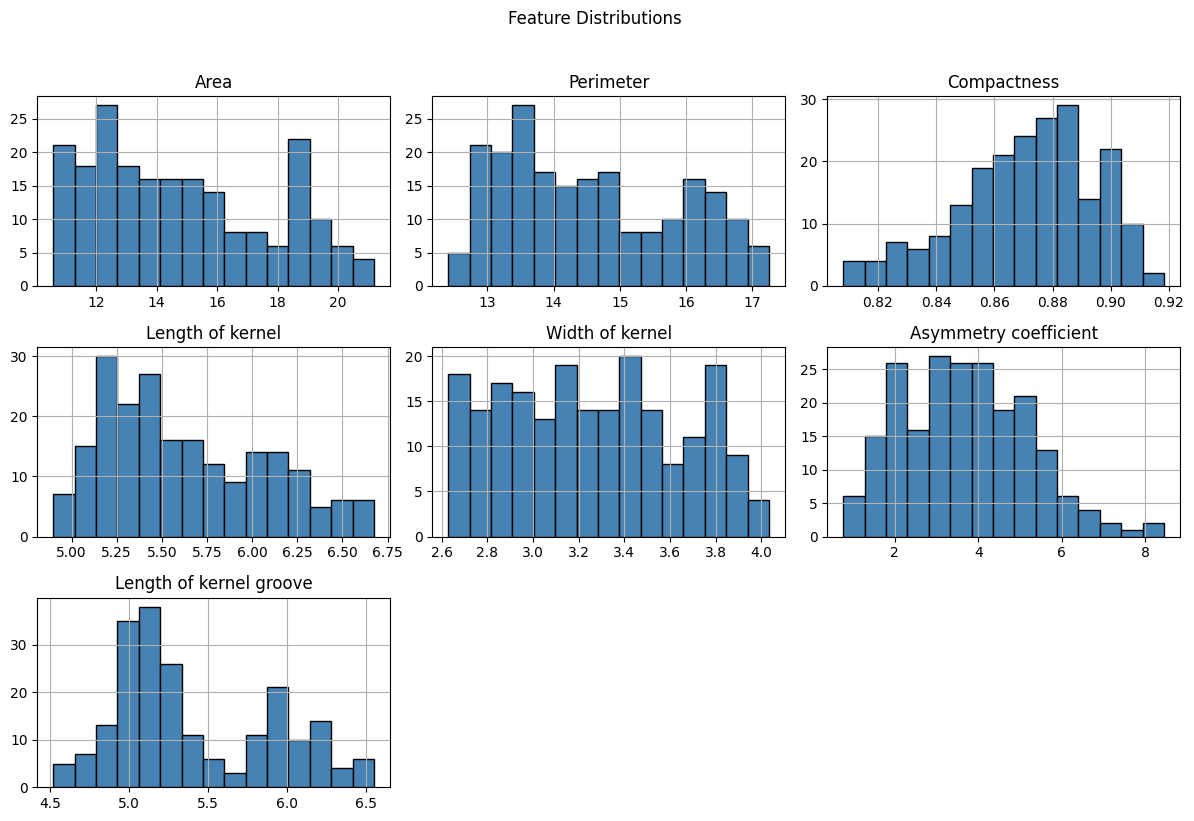

In [ ]:
features = df.columns[:-1]
df[features].hist(bins=15, figsize=(12, 8), color="steelblue", edgecolor="k")
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

mlp = MLPClassifier(hidden_layer_sizes=(8, 4),   # 2 hidden layers: 8 and 4 neurons
                    activation="relu",
                    solver="adam",
                    learning_rate_init=0.01,
                    max_iter=500,
                    random_state=42)
mlp.fit(X_train, y_train)

y_pred_mlp = mlp.predict(X_test)
print("Train accuracy: {:.2f}%".format(mlp.score(X_train, y_train) * 100))
print("Test accuracy : {:.2f}%".format(accuracy_score(y_test, y_pred_mlp) * 100))
print("Iterations run:", mlp.n_iter_)
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_mlp))
print(classification_report(y_test, y_pred_mlp))

Train accuracy: 100.00%
Test accuracy : 96.43%
Iterations run: 298
Confusion Matrix:
 [[13  1]
 [ 0 14]]
              precision    recall  f1-score   support

           0       1.00      0.93      0.96        14
           1       0.93      1.00      0.97        14

    accuracy                           0.96        28
   macro avg       0.97      0.96      0.96        28
weighted avg       0.97      0.96      0.96        28



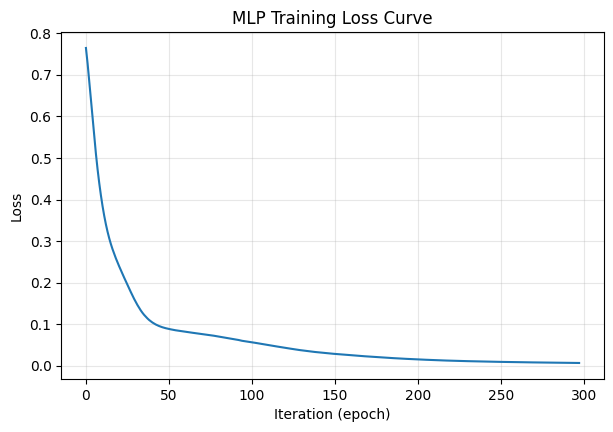

In [ ]:
plt.style.use("default")
plt.figure(figsize=(7, 4.5))
plt.plot(mlp.loss_curve_)
plt.xlabel("Iteration (epoch)"); plt.ylabel("Loss")
plt.title("MLP Training Loss Curve")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow import keras

tf.random.set_seed(42)

ann = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(8, activation="relu"),      # hidden layer 1
    keras.layers.Dense(4, activation="relu"),      # hidden layer 2
    keras.layers.Dense(1, activation="sigmoid")    # output layer (binary)
])

ann.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
            loss="binary_crossentropy",
            metrics=["accuracy"])
ann.summary()

hist_ann = ann.fit(X_train, y_train, epochs=100, batch_size=16,
                   validation_split=0.2, verbose=0)

loss, acc = ann.evaluate(X_test, y_test, verbose=0)
print(f"\nTest loss: {loss:.4f} | Test accuracy: {acc*100:.2f}%")

y_pred_ann = (ann.predict(X_test, verbose=0) > 0.5).astype(int).ravel()
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ann))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 8)              │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105 (420.00 B)

 Trainable params: 105 (420.00 B)

 Non-trainable params: 0 (0.00 B)


Test loss: 0.1017 | Test accuracy: 96.43%
Confusion Matrix:
 [[13  1]
 [ 0 14]]


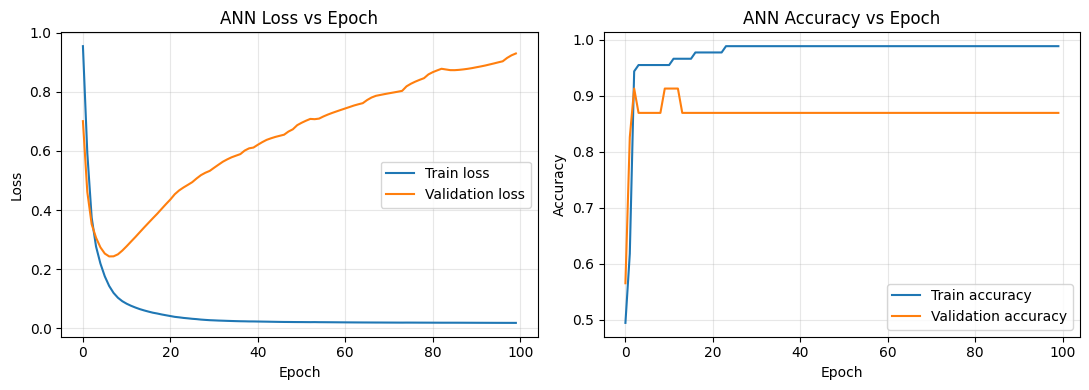

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(hist_ann.history["loss"], label="Train loss")
ax[0].plot(hist_ann.history["val_loss"], label="Validation loss")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss")
ax[0].set_title("ANN Loss vs Epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(hist_ann.history["accuracy"], label="Train accuracy")
ax[1].plot(hist_ann.history["val_accuracy"], label="Validation accuracy")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy")
ax[1].set_title("ANN Accuracy vs Epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
Xa = df.drop(columns="Class").values
ya = df["Class"].values - 1

Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.2,
                                              random_state=42, stratify=ya)
sca = StandardScaler()
Xa_tr = sca.fit_transform(Xa_tr)
Xa_te = sca.transform(Xa_te)

ann3 = keras.Sequential([
    keras.layers.Input(shape=(7,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(3, activation="softmax")
])
ann3.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
             loss="sparse_categorical_crossentropy",
             metrics=["accuracy"])

h3 = ann3.fit(Xa_tr, ya_tr, epochs=100, batch_size=16,
              validation_split=0.2, verbose=0)

loss3, acc3 = ann3.evaluate(Xa_te, ya_te, verbose=0)
print(f"3-class test accuracy: {acc3*100:.2f}%")

pred3 = np.argmax(ann3.predict(Xa_te, verbose=0), axis=1)
print("Confusion Matrix:\n", confusion_matrix(ya_te, pred3))
print(classification_report(ya_te, pred3, target_names=["Class 1", "Class 2", "Class 3"]))

3-class test accuracy: 88.10%
Confusion Matrix:
 [[ 9  2  3]
 [ 0 14  0]
 [ 0  0 14]]
              precision    recall  f1-score   support

     Class 1       1.00      0.64      0.78        14
     Class 2       0.88      1.00      0.93        14
     Class 3       0.82      1.00      0.90        14

    accuracy                           0.88        42
   macro avg       0.90      0.88      0.87        42
weighted avg       0.90      0.88      0.87        42



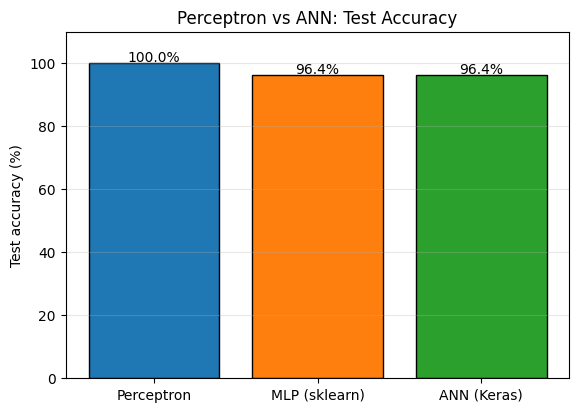

In [ ]:
from sklearn.linear_model import Perceptron

perc = Perceptron(eta0=0.1, max_iter=100, tol=None, random_state=42).fit(X_train, y_train)

names = ["Perceptron", "MLP (sklearn)", "ANN (Keras)"]
accs = [perc.score(X_test, y_test) * 100,
        accuracy_score(y_test, y_pred_mlp) * 100,
        accuracy_score(y_test, y_pred_ann) * 100]

plt.figure(figsize=(6.5, 4.5))
bars = plt.bar(names, accs, color=["tab:blue", "tab:orange", "tab:green"], edgecolor="k")
for b, a in zip(bars, accs):
    plt.text(b.get_x() + b.get_width() / 2, a + 0.5, f"{a:.1f}%", ha="center")
plt.ylim(0, 110); plt.ylabel("Test accuracy (%)")
plt.title("Perceptron vs ANN: Test Accuracy")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

knn = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)
print("Train accuracy: {:.2f}%".format(knn.score(X_train, y_train) * 100))
print("Test accuracy : {:.2f}%".format(accuracy_score(y_test, y_pred_knn) * 100))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn, target_names=["Class 2 (0)", "Class 1 (1)"]))

Train accuracy: 94.64%
Test accuracy : 96.43%
Confusion Matrix:
 [[13  1]
 [ 0 14]]
              precision    recall  f1-score   support

 Class 2 (0)       1.00      0.93      0.96        14
 Class 1 (1)       0.93      1.00      0.97        14

    accuracy                           0.96        28
   macro avg       0.97      0.96      0.96        28
weighted avg       0.97      0.96      0.96        28



Best K: 3 | Test accuracy: 100.00%


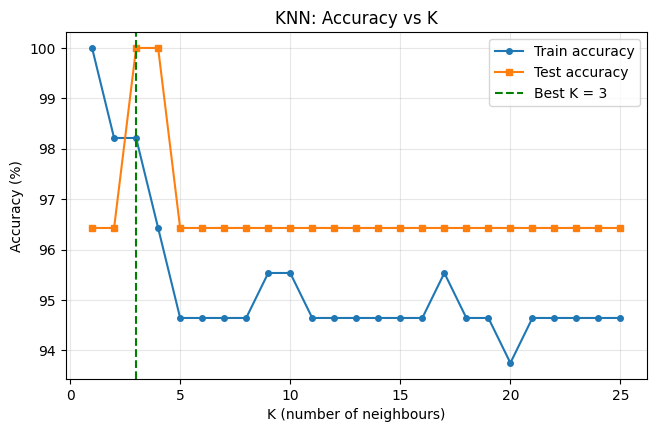

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("default")

k_values = range(1, 26)
train_acc, test_acc = [], []
for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train) * 100)
    test_acc.append(m.score(X_test, y_test) * 100)

best_k = k_values[int(np.argmax(test_acc))]
print("Best K:", best_k, "| Test accuracy: {:.2f}%".format(max(test_acc)))

plt.figure(figsize=(7.5, 4.5))
plt.plot(k_values, train_acc, marker="o", ms=4, label="Train accuracy")
plt.plot(k_values, test_acc, marker="s", ms=4, label="Test accuracy")
plt.axvline(best_k, color="g", ls="--", label=f"Best K = {best_k}")
plt.xlabel("K (number of neighbours)"); plt.ylabel("Accuracy (%)")
plt.title("KNN: Accuracy vs K"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

Best K by 5-fold CV: 1 | CV accuracy: 95.49%


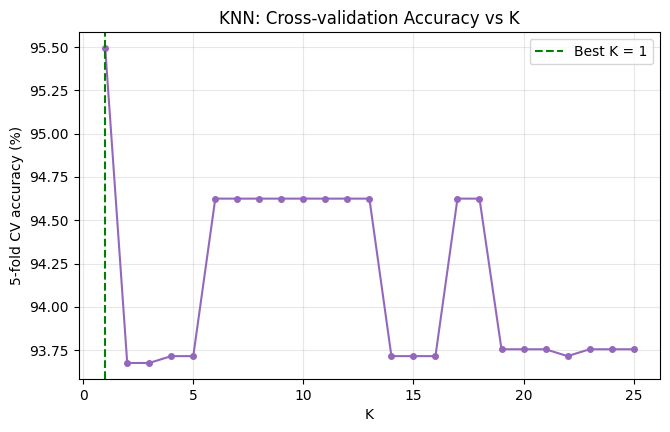

In [ ]:
from sklearn.model_selection import cross_val_score

cv_scores = []
for k in k_values:
    s = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5)
    cv_scores.append(s.mean() * 100)

best_k_cv = k_values[int(np.argmax(cv_scores))]
print("Best K by 5-fold CV:", best_k_cv, "| CV accuracy: {:.2f}%".format(max(cv_scores)))

plt.figure(figsize=(7.5, 4.5))
plt.plot(k_values, cv_scores, marker="o", ms=4, color="tab:purple")
plt.axvline(best_k_cv, color="g", ls="--", label=f"Best K = {best_k_cv}")
plt.xlabel("K"); plt.ylabel("5-fold CV accuracy (%)")
plt.title("KNN: Cross-validation Accuracy vs K"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

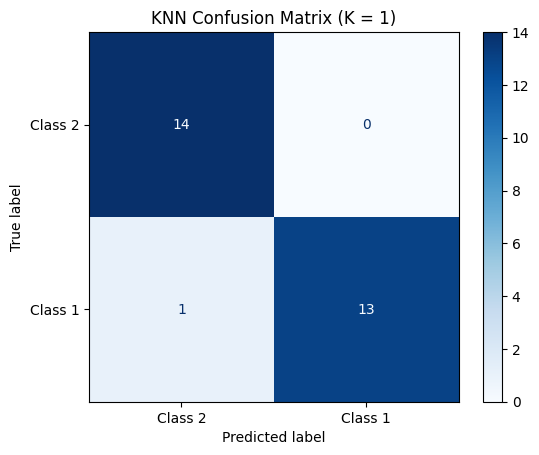

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

best = KNeighborsClassifier(n_neighbors=best_k_cv).fit(X_train, y_train)
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test,
                                      display_labels=["Class 2", "Class 1"], cmap="Blues")
plt.title(f"KNN Confusion Matrix (K = {best_k_cv})")
plt.show()

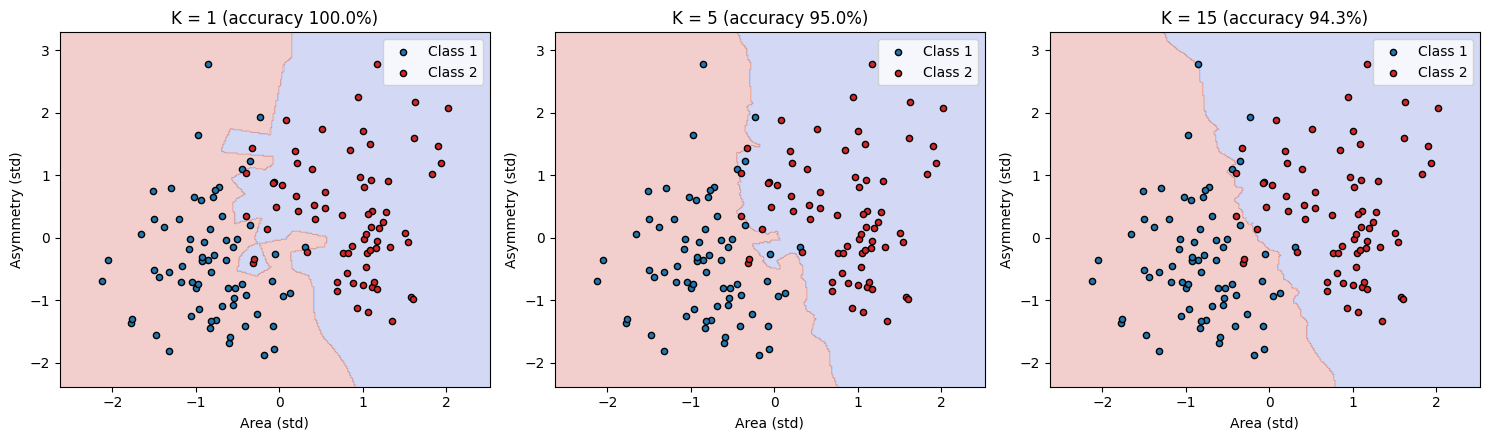

In [ ]:
from sklearn.preprocessing import StandardScaler

sub2 = df[df["Class"].isin([1, 2])]
X2 = StandardScaler().fit_transform(sub2[["Area", "Asymmetry coefficient"]].values)
y2 = np.where(sub2["Class"].values == 1, 1, 0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, k in zip(axes, [1, 5, 15]):
    m = KNeighborsClassifier(n_neighbors=k).fit(X2, y2)
    xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - .5, X2[:, 0].max() + .5, 300),
                         np.linspace(X2[:, 1].min() - .5, X2[:, 1].max() + .5, 300))
    zz = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(X2[y2 == 1, 0], X2[y2 == 1, 1], c="tab:blue", edgecolor="k", s=20, label="Class 1")
    ax.scatter(X2[y2 == 0, 0], X2[y2 == 0, 1], c="tab:red", edgecolor="k", s=20, label="Class 2")
    ax.set_title(f"K = {k} (accuracy {m.score(X2, y2)*100:.1f}%)")
    ax.set_xlabel("Area (std)"); ax.set_ylabel("Asymmetry (std)"); ax.legend()
plt.tight_layout()
plt.show()

In [ ]:

from sklearn.model_selection import train_test_split

Xa = df.drop(columns="Class").values
ya = df["Class"].values
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.2, random_state=42, stratify=ya)
sca = StandardScaler()
Xa_tr = sca.fit_transform(Xa_tr)
Xa_te = sca.transform(Xa_te)

knn3 = KNeighborsClassifier(n_neighbors=5).fit(Xa_tr, ya_tr)
pred3 = knn3.predict(Xa_te)

print("3-class test accuracy: {:.2f}%".format(accuracy_score(ya_te, pred3) * 100))
print("Confusion Matrix:\n", confusion_matrix(ya_te, pred3))
print(classification_report(ya_te, pred3, target_names=["Class 1", "Class 2", "Class 3"]))

3-class test accuracy: 90.48%
Confusion Matrix:
 [[10  2  2]
 [ 0 14  0]
 [ 0  0 14]]
              precision    recall  f1-score   support

     Class 1       1.00      0.71      0.83        14
     Class 2       0.88      1.00      0.93        14
     Class 3       0.88      1.00      0.93        14

    accuracy                           0.90        42
   macro avg       0.92      0.90      0.90        42
weighted avg       0.92      0.90      0.90        42



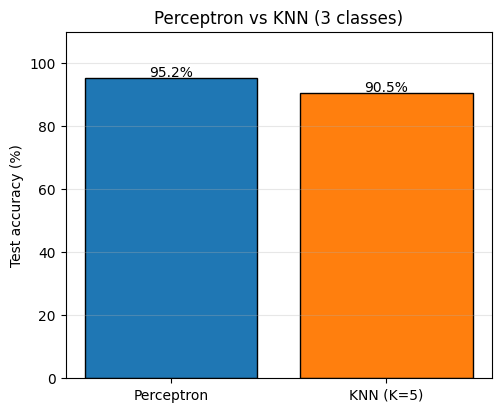

In [ ]:

from sklearn.linear_model import Perceptron

perc3 = Perceptron(eta0=0.1, max_iter=100, tol=None, random_state=42).fit(Xa_tr, ya_tr)

names = ["Perceptron", "KNN (K=5)"]
accs = [perc3.score(Xa_te, ya_te) * 100, knn3.score(Xa_te, ya_te) * 100]

plt.figure(figsize=(5.5, 4.5))
bars = plt.bar(names, accs, color=["tab:blue", "tab:orange"], edgecolor="k")
for b, a in zip(bars, accs):
    plt.text(b.get_x() + b.get_width() / 2, a + 0.5, f"{a:.1f}%", ha="center")
plt.ylim(0, 110); plt.ylabel("Test accuracy (%)")
plt.title("Perceptron vs KNN (3 classes)"); plt.grid(axis="y", alpha=0.3)
plt.show()